# Regresión Lineal
---

* Es la técnica estadística para el modelado y la investigación de la relación entre dos o más variables
* Consiste en obtener una función de aproximación que se ajuste a la forma o a la tendencia general de los datos, sin coincidir necesariamente en todos los puntos

## Ajuste de curvas

* Ajustar una curva a los datos experimentales consiste en determinar una fórmula y=f(x) que relacione las variables x e y
* Métodos:
    * Ajuste por regresión lineal en mínimos cuadrados
    * Ajuste por polinomio de grado m
    * Ajuste potencial
    * Ajuste exponencial
    * Ajuste cociente o crecimiento saturado

## Regresión Lineal Simple

### Modelos determinísticos y probabilísticos

$$y = \beta_0 + \beta_1x$$

* $x$: variable independiente
* $y$: variable dependiente

In [12]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [13]:
datosPos = pd.read_csv('doc/ia/data/datosPosicion.csv')
datosPos.head()

,Unnamed: 0,tiempo,posicion
0,1,0.0,4.639524
1,2,0.1,5.969823
2,3,0.2,8.758708
3,4,0.3,8.270508
4,5,0.4,9.329288


In [14]:
# Cantidad de datos
len(datosPos['tiempo'])

21

In [15]:
# Media de la posición
datosPos['posicion'].mean()

15.284031063976448

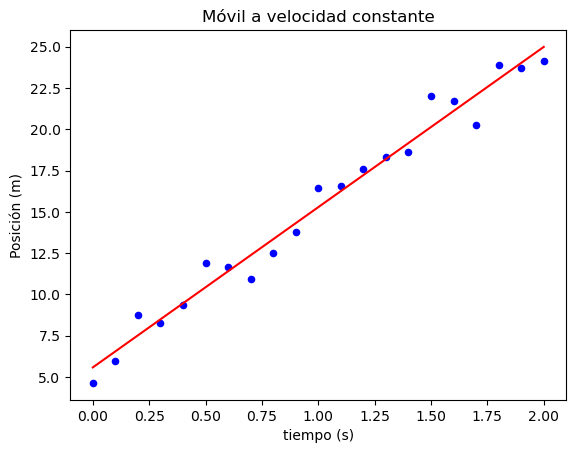

In [16]:
#Gráfico de dispersión
plt.figure()
plt.scatter(datosPos['tiempo'], datosPos['posicion'], s=20, c='blue')
plt.plot(datosPos['tiempo'], np.polyval(np.polyfit(datosPos['tiempo'], datosPos['posicion'], 1), datosPos['tiempo']), color='red')
plt.title('Móvil a velocidad constante')
plt.xlabel('tiempo (s)')
plt.ylabel('Posición (m)')
plt.show()

* Se muestran 21 mediciones realizadas en el intervalo de 0 a 2 segundos (con un tiempo de muestreo de 0,1 segundos)
* Todos los puntos no caen exactamento en una recta, pero el comportamiento lineal es evidente
* Existe un error de medición (ruido aditivo), que se puede ver como una variable aleatoria (modelo probabilístico):

$$Y = \beta_0 + \beta_1x + E$$

* Se supone:

$$E\{E\} = 0$$
$$V\{E\} = \sigma^2$$

In [17]:
trees = pd.read_csv('doc/ia/data/trees.csv')
trees.head()

,Unnamed: 0,Girth,Height,Volume
0,1,8.3,70,10.3
1,2,8.6,65,10.3
2,3,8.8,63,10.2
3,4,10.5,72,16.4
4,5,10.7,81,18.8


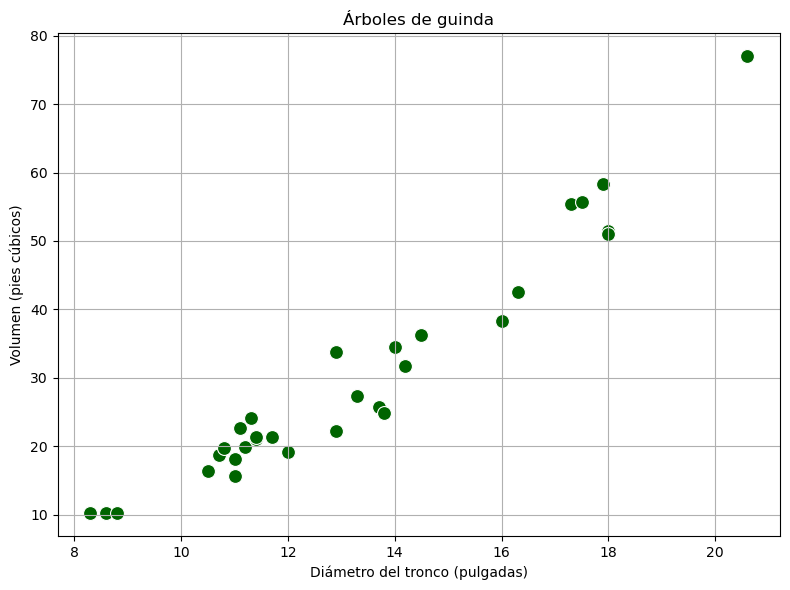

In [18]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Girth', y='Volume', data=trees, s=100, color='darkgreen')
plt.xlabel('Diámetro del tronco (pulgadas)')
plt.ylabel('Volumen (pies cúbicos)')
plt.title('Árboles de guinda')
plt.grid(True)
plt.tight_layout()
plt.show()

### Método de mínimos cuadrados

* Interés en estimar la mejor recta que explica los puntos del diagrama de dispersión
* Un enfoque puede ser minimizar las distancias a la recta:

$$e_i = y_i - (\beta_0 + \beta_1x_i)$$

* Estimaciones:

$$\hat{\beta_1} = \frac{S_{xy}}{S_{xx}}$$
$$\hat{\beta_0} = \bar{y} - \hat{\beta_1}\bar{x}$$


In [21]:
#Regresión lineal simple
n = len(datosPos['tiempo'])
xi = datosPos['tiempo']
yi = datosPos['posicion']
Sxx = np.sum(xi**2) - (np.sum(xi)**2) / n
Sxy = np.sum(xi * yi) - (np.sum(xi) * np.sum(yi)) / n
beta1_est = Sxy / Sxx
beta0_est = np.mean(yi) - beta1_est * np.mean(xi)

print(f'Sxx: {Sxx}')
print(f'Sxy: {Sxy}')

print(f'Estimación de beta0 (Ordenada al origen): {beta0_est}')
print(f'Estimación de beta1 (Pendiente): {beta1_est}')

Sxx: 7.70000000000001
Sxy: 74.72358401032119
Estimación de beta0 (Ordenada al origen): 5.57966950419449
Estimación de beta1 (Pendiente): 9.70436155978196


In [22]:
# Usando sklearn
model = LinearRegression().fit(xi.values.reshape(-1, 1), yi)
print(f'Ordenada al origen: {model.intercept_}, Pendiente: {model.coef_[0]}')

Ordenada al origen: 5.579669504194467, Pendiente: 9.704361559781983


$$y = 5.58 + 9.70x$$

In [23]:
# Calculo de las desviaciones de beta0 y beta1
SST = np.sum(yi**2) - n * (np.mean(yi)**2)
SSE = SST - beta1_est * Sxy
varSigma_est = SSE / (n - 2)

desvBeta1 = np.sqrt(varSigma_est / Sxx)
desvBeta0 = np.sqrt(varSigma_est * (1 / n + (np.mean(xi)**2) / Sxx))

print(f'Desviación típica de beta0: {desvBeta0}')
print(f'Desviación típica de beta1: {desvBeta1}')

Desviación típica de beta0: 0.4179061182014073
Desviación típica de beta1: 0.3574764433277663


$$\sigma(\hat{\beta_0}) = 0.418$$
$$\sigma(\hat{\beta_1}) = 0.357$$

### OLS (Ordinary Least Squares)

* Busca minimizar la suma de los cuadrados de los residuos (la diferencia entre los valores reales y los predichos)

In [27]:
import statsmodels.api as sm

X = datosPos[['tiempo']]
X = sm.add_constant(X)
y = datosPos['posicion']
modelo = sm.OLS(y, X).fit()
modelo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               posicion   R-squared:                       0.975
Model:                            OLS   Adj. R-squared:                  0.974
Method:                 Least Squares   F-statistic:                     737.0
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           1.16e-16
Time:                        20:56:33   Log-Likelihood:                -28.577
No. Observations:                  21   AIC:                             61.15
Df Residuals:                      19   BIC:                             63.24
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.5797      0.418     13.351      0.000       4.705       6.454
tiempo         9.7044      0.357     27.147      0.000       8.956      10.453
==============================================================================
Omnibus:                        0.216   Durbin-Watson:                   2.092
Prob(Omnibus):                  0.897   Jarque-Bera (JB):                0.412
Skew:                           0.119   Prob(JB):                        0.814
Kurtosis:                       2.356   Cond. No.                         3.63
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Test de Hipótesis sobre $\beta_1$

$$H_0: \beta_1 = \beta_{1,0}$$
$$H_1: \beta_1 \neq \beta_{1,0}$$

$$\text{Estadístico de prueba:}$$
$$T = \frac{\hat{\beta_1} - \beta_{1,0}}{\sqrt{\hat{\sigma^2} + S_{xx}}}$$

$$H_0: \beta_1 = 0$$
$$H_1: \beta_1 \neq 0$$

In [33]:
# Valor de estadístico de prueba
T0 = (beta1_est - 0) / np.sqrt(varSigma_est / Sxx)
print(f'T0: {T0}')
p_valor = 2 * (1 - stats.t.cdf(T0, n - 2))
print(f'p-valor de beta1: {p_valor}')

T0: 27.146856082161854
p-valor de beta1: 0.0


* p-valor es muy pequeño, por lo tanto, se puede concluir que la se rechaza
* Esto puede significar que existe una relación lineal entre las variables o que con un polinomio de mayor orden se obtenga un mejor resultado

$$H_0: \beta_1 = 10$$
$$H_1: \beta_1 \neq 10$$

In [34]:
# Valor de estadístico de prueba
T0 = (beta1_est - 10) / np.sqrt(varSigma_est / Sxx)
print(f'T0: {T0}')
p_valor = 2 * (stats.t.cdf(T0, n - 2))
print(f'p-valor de beta1: {p_valor}')

T0: -0.8270151662748093
p-valor de beta1: 0.4184943117900731


* En este caso, el p-valor es: 0,418. Por lo tanto, no se puede rechazar
que sea 10

### Test de Hipótesis sobre $\beta_0$

$$H_0: \beta_1 = \beta_{0,0}$$
$$H_1: \beta_1 \neq \beta_{0,0}$$

$$\text{Estadístico de prueba:}$$
$$T = \frac{\hat{\beta_0} - \beta_{0,0}}{\sqrt{\hat{\sigma^2} [\frac{1}{n} + \frac{\bar{x}^2}{S_{xx}}}]}$$